In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/bubt-artificial-intelligence-conquest-2025/sample_submission.csv
/kaggle/input/bubt-artificial-intelligence-conquest-2025/train.csv
/kaggle/input/bubt-artificial-intelligence-conquest-2025/test.csv


# **Load, Preview & Summary Stats**

This dataset is largely dependent on `Survival Analysis.` A `Random Control Trial` of D-Penicillamine has been conducted on the patients/observations (unique identifier for each person who has been diagnosed with the liver disease commonly known as `Cirrhosis` or Severe scarring of the liver. There is a training and a testing dataset for the given dataset to predict the probability of the subject either going to be deceased (D) or censored. There was a classification among the censored, which we proclaimed as the Right Censored (`C`) and Left Censored Data (`CL`).

In the initial stage, we summarized the data conventionally to see an overview of the data. Right after that, we focused on key findings through our Exploratory Data Analysis. We used some relevant methods, such as the `Kaplan Meier Estimator` (the non-parametric estimator used for the survival data). To thoroughly review the significance of the variables, we necessarily used the `Cochran–Mantel–Haenszel Test`, which acknowledges the dependence of the variables on each other. Also, basic statistical measures such as the Chi-Square Test have also been a part of our exploratory analysis. Besides, Epidemiological terms RR, ER, OR, and AR have been explained and observed for a certain case, to look forward to the observation and direct connection to subjects going censored.

In [2]:
# Importing Essentials
import os
import warnings 
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd


# EDA, Visualization and Analysis
import matplotlib.pyplot as plt
import seaborn as sns
!pip install lifetimes
!pip install lifelines
from lifelines import KaplanMeierFitter
import lifetimes as lt
%matplotlib inline
plt.style.use('ggplot')


# Statistical Analysis
from scipy import stats
from scipy.stats import chi2_contingency
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.contingency_tables import StratifiedTable
import statsmodels.formula.api as smf



# Transformations, Scaling, Encoding and Preprocessing
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import log_loss
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV


# Machine Learning Models (Monslty Classifiers, some Regressors for handling the missing values)
from xgboost import XGBClassifier


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 584.2/584.2 kB 10.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 349.3/349.3 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 7.2 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4030 sha256=214a862c77e1c82633f1113a649aac6e14f31043b7c958afbd5da6d0a581276f
  Stored in directory: /root/.cache/pip/wheels/8b/67/f4/2caaae2146198dcb824f31a303833b07b14a5ec863fb3acd7b
Successfully built autograd-gamma


In [3]:
train = pd.read_csv('/kaggle/input/bubt-artificial-intelligence-conquest-2025/train.csv')
test = pd.read_csv('/kaggle/input/bubt-artificial-intelligence-conquest-2025/test.csv')

# Reading the sizes of the Data
print(f'Size of Training data: {train.shape[0]}')
print(f'Size of Testing data: {test.shape[0]}\n\n')

# How many columns are there
print(f'Number of Columns in the Training data: {train.shape[1]}')
print(f'Number of Columns in the Testing data: {test.shape[1]}\n\n')

# Small window to preview the data
print('Preview of Training data:\n' + '-'*25 + '\n' + str(train.head(2)) + '\n' + '-'*85 + '\n')
print('Preview of Testing data:\n' + '-'*25 + '\n' + str(test.head(2)))

# Summary Statsitics of the Data
print('\n' + '='*100 + '\n')
print('Summary of the Training Data:\n' + '-'*35 + '\n' + str(train.describe(include="all")) + '\n' + '-'*85 + '\n')
print('\n' + '='*100 + '\n')
print('Summary of the Testing Data:\n' + '-'*35 + '\n' + str(test.describe(include="all")) + '\n' + '-'*85 + '\n')

# Qual-Quant Split for Training Data

cat_train = train.select_dtypes(include = ['category', 'object'])
num_train = train.select_dtypes(include = ['number', 'float64', 'int64'])


# Qual-Quant Split for Testing Data

cat_test = test.select_dtypes(include = ['category', 'object'])
num_test = test.select_dtypes(include = ['number', 'float64', 'int64'])
print(f'\n{"="*100}\n')
print(f'Categorical Columns in Training Data: {cat_train.columns.tolist()}\n')
print(f'Numerical Columns in Training Data: {num_train.columns.tolist()}\n')
print(f'Categorical Columns in Testing Data: {cat_test.columns.tolist()}\n')
print(f'Numerical Columns in Testing Data: {num_test.columns.tolist()}\n')
print(f'\n{"="*100}\n')
print(f'\n{"="*100}\n')

print(f'Null Values in Categorical Training Data:\n{"-"*40}\n{cat_train.isnull().sum()}\n{"-"*85}\n')
print(f'Null Values in Categorical Testing Data:\n{"-"*40}\n{cat_test.isnull().sum()}\n{"-"*85}\n')

print(f'\n{"="*100}\n')
print(f'Null Values in Numerical Training Data:\n{"-"*40}\n{num_train.isnull().sum()}\n{"-"*85}\n')
print(f'Null Values in Numerical Testing Data:\n{"-"*40}\n{num_test.isnull().sum()}\n{"-"*85}\n')

# Qual-Quant Split for Training Data

cat_train = train.select_dtypes(include = ['category', 'object'])
cat_train_list = cat_train.columns.tolist()

num_train = train.select_dtypes(include = ['number', 'float64', 'int64'])
num_train_list = num_train.columns.tolist()

# Qual-Quant Split for Testing Data

cat_test = test.select_dtypes(include = ['category', 'object'])
cat_test_list = cat_test.columns.tolist()

num_test = test.select_dtypes(include = ['number', 'float64', 'int64'])
num_test_list = num_test.columns.tolist()

# Analyzing the Columns
print(f'\n{"="*100}\n')
print(f'Categorical Columns in Training Data: {cat_train.columns.tolist()}\n')
print(f'Numerical Columns in Training Data: {num_train.columns.tolist()}\n')
print(f'Categorical Columns in Testing Data: {cat_test.columns.tolist()}\n')
print(f'Numerical Columns in Testing Data: {num_test.columns.tolist()}\n')
print(f'\n{"="*100}\n')
print(f'\n{"="*100}\n')


# Finding the Null values in Categorical and Numerical Data
print(f'Null Values in Categorical Training Data:\n{"-"*40}\n{cat_train.isnull().sum()}\n{"-"*85}\n')
print(f'Null Values in Categorical Testing Data:\n{"-"*40}\n{cat_test.isnull().sum()}\n{"-"*85}\n')

print(f'\n{"="*100}\n')
print(f'Null Values in Numerical Training Data:\n{"-"*40}\n{num_train.isnull().sum()}\n{"-"*85}\n')
print(f'Null Values in Numerical Testing Data:\n{"-"*40}\n{num_test.isnull().sum()}\n{"-"*85}\n')

# Outlier Detection and Removal using IQR Method
class Outliers:
    def __init__(self, df: pd.DataFrame, cols: list, range: float = 1.5):
        self.df = df.copy()
        self.cols = cols
        self.range = range
    
    def observe(self):
        data = self.df
        mask = pd.Series(True, index=data.index)  # start with all rows valid
        lower_outlier = []
        upper_outlier = []
        
        for col in self.cols:
            q1 = data[col].quantile(0.25)
            q3 = data[col].quantile(0.75)
            iqr = q3 - q1
            lb = q1 - iqr * self.range
            ub = q3 + iqr * self.range
            
            # collect outliers
            lower_outlier.append(data[data[col] < lb])
            upper_outlier.append(data[data[col] > ub])
            
            # update mask (row must be within bounds for ALL cols)
            mask &= (data[col] >= lb) & (data[col] <= ub)
        
        # final cleaned dataset
        cleaned_data = data[mask]
        
        return pd.concat(lower_outlier), pd.concat(upper_outlier), cleaned_data
train2 = train.copy()
outlier_detector = Outliers(df=train2, cols=num_train_list, range=3)
lower_outliers, upper_outliers, cleaned_data = outlier_detector.observe()

print(f'\n{"="*100}\n')
# Summarizing the ends of the outliers
print(f'Outlier Detection Summary:\n{"-"*35}')
print(f'Number of Lower Outliers Detected: {lower_outliers.shape[0]}')
print(f'Number of Upper Outliers Detected: {upper_outliers.shape[0]}')
print(f'Number of Rows after Outlier Removal: {cleaned_data.shape[0]}')

# Summary Statistics after Outlier Removal
print(f'\n{"="*100}\n')
print(f'Summary Statistics after Outlier Removal:\n{"-"*45}\n{cleaned_data.describe(include = "all")}\n{"-"*85}\n')

Size of Training data: 15000
Size of Testing data: 10000


Number of Columns in the Training data: 20
Number of Columns in the Testing data: 19


Preview of Training data:
-------------------------
   id  N_Days     Drug      Age Sex Ascites Hepatomegaly Spiders Edema  \
0   0   859.0  Placebo  17841.0   F       N            Y       N     N   
1   1  1141.0  Placebo  18102.0   F       N            Y       Y     S   

   Bilirubin  Cholesterol  Albumin  Copper  Alk_Phos    SGOT  Tryglicerides  \
0        2.1        396.0     3.70    74.0    2148.0  136.74          144.0   
1        2.1        187.0     3.48     4.0     918.0  120.90           90.0   

   Platelets  Prothrombin  Stage Status  
0      298.0         11.0    4.0      D  
1      213.0         12.4    2.0      D  
-------------------------------------------------------------------------------------

Preview of Testing data:
-------------------------
      id  N_Days Drug      Age Sex Ascites Hepatomegaly Spiders Edema  \
0  1

## **Subsetting & Creating New Variables or List**

In [4]:
# Variables
train['N_years'] = (train['N_Days'] / 365.25).astype(int)
train['Status2'] = ['Dead' if status == 'D' else 'Alive' for status in train['Status']]
train['Status3'] = train['Status2'].map({'Alive':0, 'Dead':1}) # Assuming if not dead they are alive or censored

# Lists
expose_groups = ['Ascites', 'Hepatomegaly', 'Spiders', 'Edema']
cat_train_cmh_list = cat_train.drop(columns='Status').columns.to_list()

# RCT wise subsetting
placebo = train[train['Drug'] == 'Placebo']
D_penicillamine = train[train['Drug'] == 'D-penicillamine']
rct_train = train[train['Drug'] != np.NaN]

# **Handling Missing values**
Finding associations between variables to measure the necessity of variables.

In [5]:
# Why do we have so many missing data?
print(pd.crosstab(train['Stage'], train['Status']))
print('We can say most of the observations went missing after 3rd stage')
print(
    f"Subjects who went through the process of proper drug:\n"
    f"{D_penicillamine.isna().sum()}\n"
    f"{'-'*25}\n"
    "So, it is seen that missing data significantly reduced due to filtering only the drugged subjects."
)


Status     C   CL     D
Stage                  
1.0      745    5    45
2.0     2756   74   496
3.0     4724  121   951
4.0     2009  143  2931
We can say most of the observations went missing after 3rd stage
Subjects who went through the process of proper drug:
id                  0
N_Days              0
Drug                0
Age                 0
Sex                 0
Ascites             9
Hepatomegaly       10
Spiders            10
Edema               0
Bilirubin           0
Cholesterol      1240
Albumin             0
Copper             76
Alk_Phos            9
SGOT               10
Tryglicerides    1268
Platelets         151
Prothrombin         0
Stage               0
Status              0
N_years             0
Status2             0
Status3             0
dtype: int64
-------------------------
So, it is seen that missing data significantly reduced due to filtering only the drugged subjects.


# **Visualization and Interpretation**

### **The Kaplan–Meier estimator**
The estimator of the survival function 
$S(t){\displaystyle S(t)}$ (the probability that life is longer than $t$ is given by:
${\displaystyle {\widehat {S}}(t)=\prod \limits _{i:\ t_{i}\leq t}\left(1-{\frac {d_{i}}{n_{i}}}\right),}$

with $t_i$ a time when at least one event happened, di the number of events (e.g., deaths) that happened at time $t_i$, and $n_i$ the individuals known to have survived (have not yet had an event or been censored) up to time 
$t_i$

*Source: [wikipedia](https://en.wikipedia.org/wiki/Kaplan%E2%80%93Meier_estimator)*

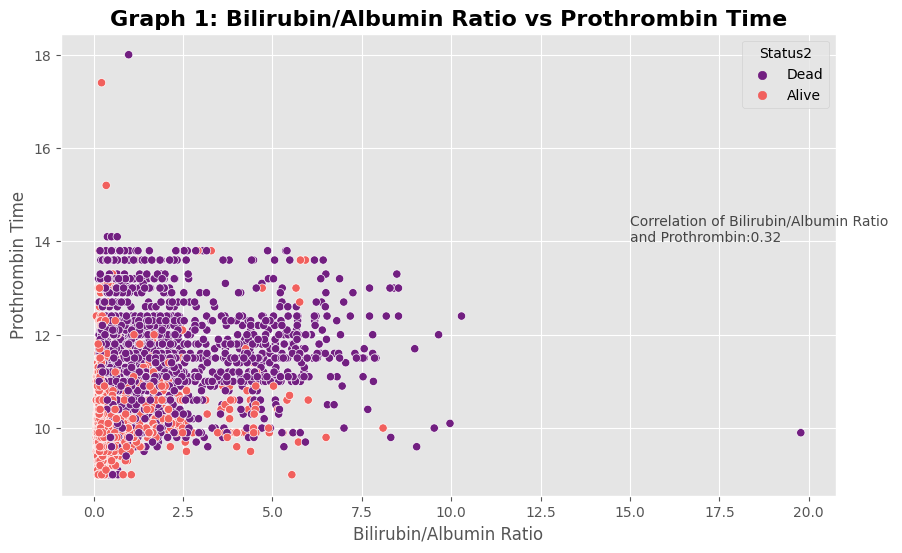

In [6]:
# Creating a few variables for a better preview of the data
train['bilirubin_albumin_ratio'] = train['Bilirubin'] / train['Albumin']
plt.figure(figsize=(10,6))
sns.scatterplot(data = train, x = 'bilirubin_albumin_ratio', y = 'Prothrombin', hue = 'Status2', palette = 'magma')
plt.text(15, 14, f'Correlation of Bilirubin/Albumin Ratio \nand Prothrombin:{train["bilirubin_albumin_ratio"].corr(train["Prothrombin"]):.2f}', fontsize=10, color = 'black', alpha = 0.7)
plt.ylabel('Prothrombin Time')
plt.xlabel('Bilirubin/Albumin Ratio')
plt.title('Graph 1: Bilirubin/Albumin Ratio vs Prothrombin Time', fontdict={'fontsize':16, 'fontweight':'bold'})
plt.show()

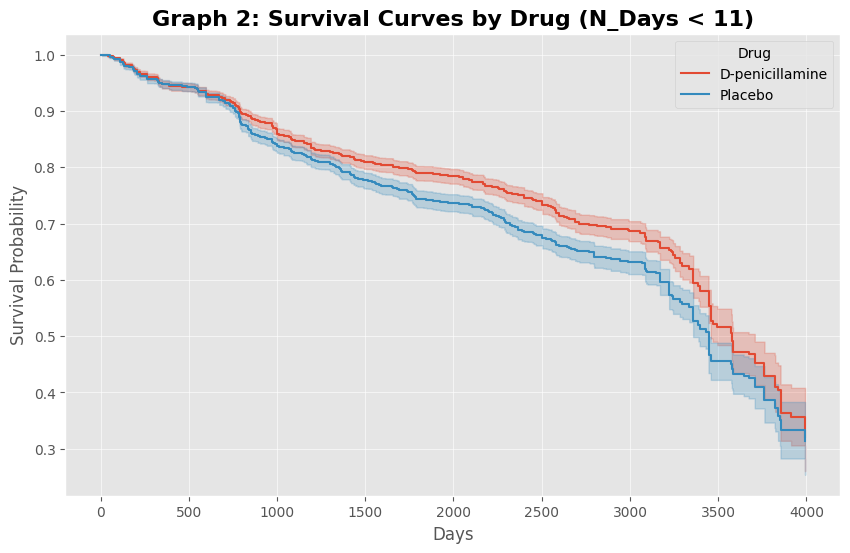

In [7]:
kmf = KaplanMeierFitter()

plt.figure(figsize=(10,6))

for drug, df in train.groupby("Drug"):

    # Filter BOTH durations and events
    sub = df[df["N_Days"] < 11*365.25].copy()

    durations = sub["N_Days"]
    events = sub["Status"].apply(lambda x: 1 if x == 'D' else 0)

    kmf.fit(durations=durations, event_observed=events, label=drug)
    kmf.plot_survival_function()

plt.title("Graph 2: Survival Curves by Drug (N_Days < 11)", fontdict={'fontsize':16, 'fontweight':'bold'})
plt.grid(True, alpha = 0.6)
plt.xlabel("Days")
plt.ylabel("Survival Probability")
plt.legend(title='Drug')
plt.show()

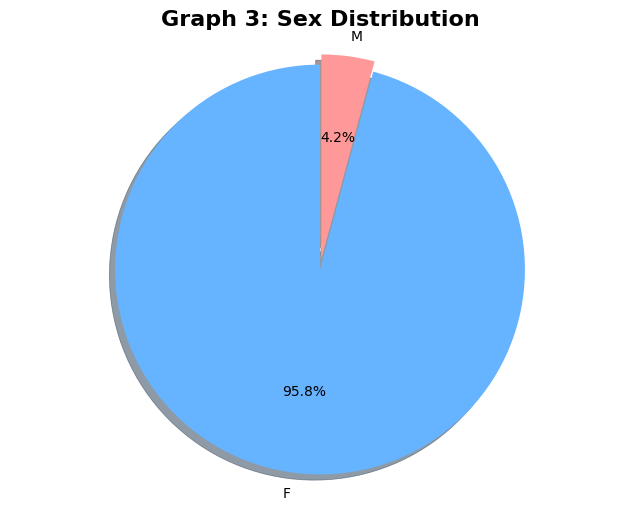

In [8]:
sex_counts = train['Sex'].value_counts()

plt.figure(figsize=(8,6))
plt.pie(
    sex_counts,
    labels=sex_counts.index,              # add labels (Male/Female)
    autopct='%1.1f%%',                    # show percentages
    startangle=90,                        # start from top
    colors=['#66b3ff','#ff9999'],         # custom colors
    explode=(0.05, 0),                    # slightly separate first slice
    shadow=True                           # add shadow for depth
)

plt.title('Graph 3: Sex Distribution', fontsize=16, fontweight='bold')
plt.axis('equal') 
plt.show()

## **Conclusion of visualization**
**Graph 1 (Bilirubin/Albumin Ratio vs Prothrombin given Dead or Alive :** *The graph shows that even though the Ratio of Bilirubin/Albumin and Prothrombin does not have much Pearson's Correlation of Linear association, but either of their high value can be the reason for death for most of the given patients.*

**Graph 2 (Kaplan Meier Estimator for year less than euqals to 10):** *We have seen some notable gaps in `Survival Probability` between drugged (D-penicillamines) and placebo subjects (Only when the observation is observed for the starting 10 years). However, the latter part does not reveal any significance. We need to identify the confounder so that we can determine the primary cause of this biased outcome.*

**Upcoming Approach:** `Cochran-Hanzel-Mantel Test` for the groups.

# **Epidemiological Metrics and Statistical Analysis**

## **Description and Terminologies**

- **Relative Risk (RR):** Relative Risk gives us insight into the effect of any Exposed Group compared to the Non-Exposed Group when the outcome is Dead or Alive. It quantifies how much more (or less) likely death is in the exposed group relative to the non-exposed group.

- **Excess Risk (ER):** Excess Risk measures the absolute difference in risk between the Exposed and Non-Exposed groups. It tells us how many additional deaths occur in the exposed group compared to the baseline risk in the non-exposed group.

- **Odds Ratio (OR):** Odds Ratio compares the odds of death in the Exposed Group to the odds of death in the Non-Exposed Group. It is particularly useful in case-control studies and when the outcome is rare, as it approximates the Relative Risk.

- **Attributable Risk (AR):** Attributable Risk represents the proportion of deaths in the Exposed Group that can be attributed to the exposure itself. It highlights the public health impact of the exposure by showing how much of the risk could theoretically be eliminated if the exposure were removed.

- **Chi-Square (χ²):** The Chi-Square test evaluates whether the observed differences in death rates between Exposed and Non-Exposed groups are statistically significant. It checks if the association is likely due to chance or reflects a real effect of exposure.

## **Drug vs Status**
*Comparing Drug and Patients count through a crosstable (also known as a contingency table). Calculated the RR, ER, OR, and AR. Finally, measuring the significance of this particular variable with respect to status using the Chi-Square Test and looking forward to its p-value.*

### **Code and Output**

In [9]:
# Epidemiological Analysis for the Drug Effectiveness through Crosstab and Randomized Controlled Trial (RCT)

ct = pd.crosstab(train['Drug'], train['Status2'], margins=True)
print(ct)

dead_pen = ct.loc["D-penicillamine", "Dead"]
alive_pen = ct.loc["D-penicillamine", "Alive"]
total_pen = ct.loc["D-penicillamine", "All"]

dead_placebo = ct.loc["Placebo", "Dead"]
alive_placebo = ct.loc["Placebo", "Alive"]
total_placebo = ct.loc["Placebo", "All"]

risk_pen = dead_pen / total_pen
risk_placebo = dead_placebo / total_placebo
RR = risk_pen / risk_placebo
ER = risk_pen - risk_placebo
AR = 1 / ER if ER != 0 else np.inf
AR_percent = (AR / risk_pen) * 100
OR = (dead_pen / alive_pen) / (dead_placebo / alive_placebo)
print('='*150)
print(f'Relative Risk (RR) of Death with D-penicillamine vs Placebo: {RR:.2f}\nWhich indicates that the risk of death for patients treated with D-penicillamine is {RR:.2f} times that of patients given a placebo.\n')
print(f'Excess Risk (ER) of Death with D-penicillamine vs Placebo: {ER:.2f}\nThis means that there is an absolute increase of {ER:.2f} in the risk of death when using D-penicillamine compared to placebo.\n')
print(f'Attributed Risk (AR): {AR:.2f}\nThis suggests that for every {AR:.2f} patients treated with D-penicillamine, one additional death occurs that would not have occurred if they had received the placebo.\n')
print(f'Odds Ratio (OR) of Death with D-penicillamine vs Placebo: {OR:.2f}\nThis indicates that the odds of death for patients treated with D-penicillamine are {OR:.2f} times the odds for patients given a placebo.\n')


chi2, p, dof, expected = chi2_contingency(ct)

print("="*120)
print(f"Chi-square statistic: {chi2:.2f}")
print(f"Degrees of freedom: {dof}")
print("Expected frequencies:\n", expected)
print(f"P-value: {p:.4f}")


Status2          Alive  Dead   All
Drug                              
D-penicillamine   3263  1238  4501
Placebo           2715  1241  3956
All               5978  2479  8457
Relative Risk (RR) of Death with D-penicillamine vs Placebo: 0.88
Which indicates that the risk of death for patients treated with D-penicillamine is 0.88 times that of patients given a placebo.

Excess Risk (ER) of Death with D-penicillamine vs Placebo: -0.04
This means that there is an absolute increase of -0.04 in the risk of death when using D-penicillamine compared to placebo.

Attributed Risk (AR): -25.87
This suggests that for every -25.87 patients treated with D-penicillamine, one additional death occurs that would not have occurred if they had received the placebo.

Odds Ratio (OR) of Death with D-penicillamine vs Placebo: 0.83
This indicates that the odds of death for patients treated with D-penicillamine are 0.83 times the odds for patients given a placebo.

Chi-square statistic: 15.18
Degrees of freedo

### **Conclusion and Decision:**

As it is seen, the `D-penicillamine` has a high effect on the situation. To confirm that, we have acquired a `p-value` of `0.0043 (<0.01)`, which determines the high significance of the Drug used in this `Randomized Controlled Trial (RCT)` experiment. In addition, we have a `Chi-square Score` of `15.18`, also indicates a high association between the groups (`Drug` & `Status`)

## **Exposeure Group Analysis**
Exposure Group as in `Ascites`, `Hepatomegaly`, `Spiders`, and `Edema`
Mostly done Cochran–Mantel–Haenszel Test for the given formula:
Odds Ratio, ${\displaystyle R={{\sum _{i=1}^{K}{\frac {A_{i}D_{i}}{T_{i}}}} \over {\sum _{i=1}^{K}{B_{i}C_{i} \over T_{i}}}},}$

and the Chi-Square Distribution test under the null hypothesis for ${\displaystyle H_{0}:R=1}$ and the alternative hypothesis is ${\displaystyle H_{1}:R\neq 1}$ to get,

${\displaystyle \xi _{\text{CMH}}={\frac {\left[\sum _{i=1}^{K}\left(A_{i}-{\frac {N_{1i}M_{1i}}{T_{i}}}\right)\right]^{2}}{\sum _{i=1}^{K}{N_{1i}N_{2i}M_{1i}M_{2i} \over T_{i}^{2}(T_{i}-1)}}}.}$

*Source: [wikipedia](https://en.wikipedia.org/wiki/Cochran%E2%80%93Mantel%E2%80%93Haenszel_statistics)*

### **Code and Output**

In [10]:
model = smf.logit("Status3 ~ Ascites + Hepatomegaly + Spiders + Edema + Cholesterol + Albumin + Bilirubin + Copper + Alk_Phos + Platelets + Tryglicerides + Stage + SGOT", data=rct_train).fit()
print(model.summary())

Optimization terminated successfully.
         Current function value: 0.358025
         Iterations 14
                           Logit Regression Results                           
Dep. Variable:                Status3   No. Observations:                 6313
Model:                          Logit   Df Residuals:                     6297
Method:                           MLE   Df Model:                           15
Date:                Thu, 27 Nov 2025   Pseudo R-squ.:                  0.4079
Time:                        15:32:36   Log-Likelihood:                -2260.2
converged:                       True   LL-Null:                       -3817.6
Covariance Type:            nonrobust   LLR p-value:                     0.000
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            -0.4299   5.45e+06  -7.89e-08      1.000   -1.07e+07    1.07e+07
Ascites

In [11]:
# Cochran–Mantel–Haenszel Test with Confounders but only based on subsetting the drug D-penicillamine and Placebo 
cat_train_cmh_list = rct_train.drop(columns=['Status', 'Drug']).columns.to_list()

confounders = [
    'Albumin', 'Bilirubin', 'Cholesterol', 'Copper',
    'Alk_Phos', 'SGOT', 'Tryglicerides',
    'Platelets', 'Prothrombin', 'Stage'
]

for conf in confounders:
    conf_cat = f"{conf}_cat"
    
    # If numeric, bin into quartiles
    if pd.api.types.is_numeric_dtype(rct_train[conf]):
        rct_train[conf_cat] = pd.qcut(rct_train[conf], q=4, labels=False, duplicates='drop')
    else:
        rct_train[conf_cat] = rct_train[conf]
    
    for col in cat_train_cmh_list:
        tables = []
        for level in rct_train[conf_cat].dropna().unique():
            subset = rct_train[rct_train[conf_cat] == level]
            ct = pd.crosstab(subset[col], subset['Status3'])
            if ct.shape == (2, 2):
                tables.append(ct.values)
        if tables:
            cmh = StratifiedTable(tables)
            print(f"{col} with {conf} confounding")
            print("CMH statistic:", cmh.test_null_odds().statistic)
            print("p-value:", cmh.test_null_odds().pvalue)
            print("Pooled Odds Ratio:", cmh.oddsratio_pooled)
            print("="*50)


Sex with Albumin confounding
CMH statistic: 191.0425405641481
p-value: 0.0
Pooled Odds Ratio: 3.065708835560396
Ascites with Albumin confounding
CMH statistic: 461.6516084020867
p-value: 0.0
Pooled Odds Ratio: 58.68674459752496
Hepatomegaly with Albumin confounding
CMH statistic: 1233.4064086415449
p-value: 0.0
Pooled Odds Ratio: 6.942776005208345
Spiders with Albumin confounding
CMH statistic: 579.456704816306
p-value: 0.0
Pooled Odds Ratio: 4.986590603460126
Status2 with Albumin confounding
CMH statistic: 14253.066282392023
p-value: 0.0
Pooled Odds Ratio: inf
Status3 with Albumin confounding
CMH statistic: 14253.066282392023
p-value: 0.0
Pooled Odds Ratio: inf
Sex with Bilirubin confounding
CMH statistic: 60.41201281315926
p-value: 7.66053886991358e-15
Pooled Odds Ratio: 2.0142332505096063
Ascites with Bilirubin confounding
CMH statistic: 275.7041648581615
p-value: 0.0
Pooled Odds Ratio: 40.86817682064508
Hepatomegaly with Bilirubin confounding
CMH statistic: 576.233055900718
p-value

# **Feature and Model Evaluation**

In [12]:

def process_data():
    train = pd.read_csv("/kaggle/input/bubt-artificial-intelligence-conquest-2025/train.csv")
    test = pd.read_csv("/kaggle/input/bubt-artificial-intelligence-conquest-2025/test.csv")
    
    train_ids = train['id']
    test_ids = test['id']
    
    rct_train_idx = train[train['Drug'].notna()].index
    nonrct_train_idx = train[train['Drug'].isna()].index
    rct_test_idx = test[test['Drug'].notna()].index
    nonrct_test_idx = test[test['Drug'].isna()].index

    y = train['Status']
    le_target = LabelEncoder()
    y_enc = le_target.fit_transform(y)
    
    train = train.drop(['id', 'Status'], axis=1)
    test = test.drop(['id'], axis=1)
    
    combined = pd.concat([train, test], axis=0)
    
    cat_cols = ['Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema']
    for col in cat_cols:
        combined[col] = combined[col].astype(str)
        le = LabelEncoder()
        combined[col] = le.fit_transform(combined[col])
        
    num_cols = ['N_Days', 'Age', 'Bilirubin', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Platelets', 'Prothrombin', 'Stage']
    imp = SimpleImputer(strategy='median')
    combined[num_cols] = imp.fit_transform(combined[num_cols])
    
    X_train = combined.iloc[:len(train)]
    X_test = combined.iloc[len(train):]
    
    cat_rct = ['Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema']
    num_rct = ['N_Days', 'Age', 'Bilirubin', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Platelets', 'Prothrombin', 'Stage']
    features_rct = cat_rct + num_rct
    
    cat_non = ['Sex', 'Edema']
    num_non = ['N_Days', 'Age', 'Bilirubin', 'Albumin', 'Platelets', 'Prothrombin', 'Stage']
    features_non = cat_non + num_non
    
    X_train_rct = X_train.loc[rct_train_idx, features_rct]
    y_train_rct = y_enc[rct_train_idx]
    
    X_train_non = X_train.loc[nonrct_train_idx, features_non]
    y_train_non = y_enc[nonrct_train_idx]
    
    X_test_rct = X_test.loc[rct_test_idx, features_rct]
    X_test_non = X_test.loc[nonrct_test_idx, features_non]
    
    # Define Parameter Grid
    # Expanded grid for extensive search
    param_grid = {
    'n_estimators': [500, 1000],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [4, 6, 8],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
    }
    
    print("Tuning RCT Model...")
    xgb_rct = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss')
    grid_rct = GridSearchCV(estimator=xgb_rct, param_grid=param_grid, scoring='neg_log_loss', cv=3, verbose=1, n_jobs=-1)
    grid_rct.fit(X_train_rct, y_train_rct)
    
    best_rct = grid_rct.best_estimator_
    print(f"Best RCT Params: {grid_rct.best_params_}")
    preds_rct = best_rct.predict_proba(X_test_rct)
    
    print("Tuning Non-RCT Model...")
    xgb_non = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='mlogloss')
    grid_non = GridSearchCV(estimator=xgb_non, param_grid=param_grid, scoring='neg_log_loss', cv=3, verbose=1, n_jobs=-1)
    grid_non.fit(X_train_non, y_train_non)
    
    best_non = grid_non.best_estimator_
    print(f"Best Non-RCT Params: {grid_non.best_params_}")
    preds_non = best_non.predict_proba(X_test_non)
    
    df_rct_preds = pd.DataFrame(preds_rct, index=rct_test_idx, columns=['Status_C', 'Status_CL', 'Status_D'])
    df_non_preds = pd.DataFrame(preds_non, index=nonrct_test_idx, columns=['Status_C', 'Status_CL', 'Status_D'])
    
    final_preds = pd.concat([df_rct_preds, df_non_preds]).sort_index()
    
    submission = pd.DataFrame({
        'id': test_ids,
        'Status_C': final_preds['Status_C'],
        'Status_CL': final_preds['Status_CL'],
        'Status_D': final_preds['Status_D']
    })
    
    submission.to_csv("submission.csv", index=False)
    print("Submission saved to submission.csv")

if __name__ == "__main__":
    process_data()

Tuning RCT Model...
Fitting 3 folds for each of 72 candidates, totalling 216 fits
Best RCT Params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 1000, 'subsample': 0.8}
Tuning Non-RCT Model...
Fitting 3 folds for each of 72 candidates, totalling 216 fits
Best Non-RCT Params: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 1000, 'subsample': 0.8}
Submission saved to submission.csv
